In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
import pandas as pd
import numpy as np

## Данные соревнования МТС: https://ods.ai/competitions/competition-recsys-21/data

In [2]:
# Зависимости: pandas, numpy, scipy, scikit-learn, implicit, torch, tqdm, matplotlib.
# При необходимости установите их в окружение ядра Jupyter.

In [3]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_URL = "https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv"
data_path = Path.home() / ".cache" / "recsys_seminar4" / "interactions.csv"
data_path.parent.mkdir(parents=True, exist_ok=True)
if not data_path.exists():
    tmp_path = data_path.with_suffix(".download")
    urlretrieve(DATA_URL, tmp_path)
    tmp_path.replace(data_path)
print(data_path)

C:\Users\Иван\.cache\recsys_seminar4\interactions.csv


In [4]:
df = pd.read_csv(data_path)
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [5]:
dates = pd.to_datetime(df["last_watch_dt"])
df["last_watch_dt"] = (dates - dates.min()).dt.days
df.sample(5, random_state=42)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
3782044,772446,14431,4,7113,100.0
905919,263895,13865,160,8653,100.0
1137319,754998,2887,119,137,2.0
2835718,593177,15886,47,9127,100.0
1275130,236930,8486,32,797,13.0


In [6]:
df.shape, df['user_id'].nunique(), df['item_id'].nunique()

((5476251, 5), 962179, 15706)

<Axes: >

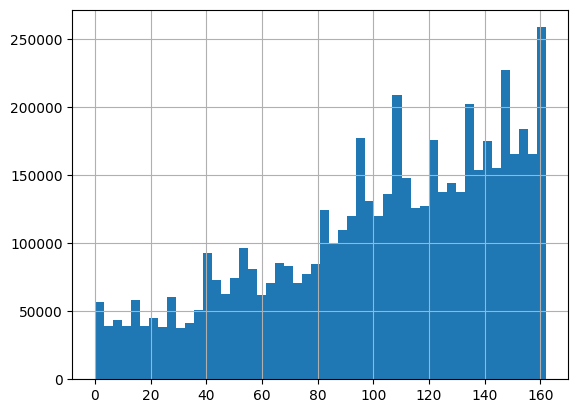

In [7]:
df['last_watch_dt'].hist(bins=50)

In [8]:
max_watch_dt = df['last_watch_dt'].max()
max_watch_dt

162

#### Разобьем датасет на трейн и тест. в тест отправим все события за последние 30 дней, в трейн все остальное. Посчитаем число уникальных юзеров в трейне и тесте, и юзеров, которые есть и там и там. Затем оставим в тесте только тех юзеров/айтемы, которые есть в трейне

In [9]:
# your code here
# Граница включена в тест: от max_date - 30 дней до max_date включительно.
train_df = df[df.last_watch_dt < max_watch_dt - 30].copy()
test_df = df[df.last_watch_dt >= max_watch_dt - 30].copy()
print("Пользователей в train:", train_df.user_id.nunique())
print("Пользователей в test:", test_df.user_id.nunique())
print("Общих пользователей:", len(set(train_df.user_id) & set(test_df.user_id)))
assert train_df.shape[0] == 3740952
assert test_df.shape[0] == 1735299

Пользователей в train: 720875
Пользователей в test: 434353


Общих пользователей: 193049


In [10]:
# your code here
old_shape = len(test_df)
test_df = test_df[test_df.user_id.isin(train_df.user_id) & test_df.item_id.isin(train_df.item_id)].copy()
assert test_df.shape[0] == 851974
assert test_df['user_id'].nunique() == 186701
assert test_df['item_id'].nunique() == 8867
print(f"Строк после фильтрации: {len(test_df)}, удалено {old_shape - len(test_df)} ({100 * (old_shape-len(test_df))/old_shape:.2f}%)")
print(f"Пользователей в тесте: {test_df.user_id.nunique()}")

Строк после фильтрации: 851974, удалено 883325 (50.90%)


Пользователей в тесте: 186701


#### Насэмплируем 50_000 юзеров которые есть и в трейне и в тесте и ограничим тестовую и трейновую выборку только этими пользователями

In [11]:
np.random.seed(42)
train_users = train_df['user_id'].unique()
test_users = test_df.user_id.unique()
n_users = 50_000
# your_code_here
sampled_users = np.random.choice(test_users, size=n_users, replace=False)
train_df = train_df[train_df.user_id.isin(sampled_users)].copy()
test_df = test_df[test_df.user_id.isin(sampled_users)].copy()
assert train_df['last_watch_dt'].max() < test_df['last_watch_dt'].min()
assert train_df['user_id'].nunique() == n_users
assert test_df['user_id'].nunique() == n_users

In [12]:
train_items = train_df['item_id'].unique()
test_df = test_df[test_df['item_id'].isin(train_items)].copy()
# Повторные просмотры исключаем из цели: модели не рекомендуют уже виденные объекты.
seen_pairs = train_df[['user_id', 'item_id']].drop_duplicates()
before = len(test_df)
test_df = test_df.merge(seen_pairs.assign(seen=True), on=['user_id', 'item_id'], how='left')
test_df = test_df[test_df.seen.isna()].drop(columns='seen')
print('Повторных просмотров исключено:', before - len(test_df))

Повторных просмотров исключено: 0


In [13]:
print(train_df['user_id'].nunique(), train_df['item_id'].nunique())
print(test_df['user_id'].nunique(), test_df['item_id'].nunique())
print(train_df.shape, test_df.shape)

50000 10087
49956 6116
(480236, 5) (226267, 5)


In [14]:
def dcg(scores):
    scores = np.asarray(scores, dtype=float)
    return np.sum(scores / np.log2(np.arange(len(scores)) + 2))

def ndcg_metric(gt_items, predicted):
    gt = set(gt_items)
    predicted = list(dict.fromkeys(predicted))
    relevance = [int(item in gt) for item in predicted]
    ideal = dcg(np.ones(min(len(gt), len(predicted))))
    return dcg(relevance) / ideal if ideal else 0.0

def recall_metric(gt_items, predicted):
    gt = set(gt_items)
    return len(gt.intersection(predicted)) / len(gt) if gt else 0.0

def evaluate_recommender(df, model_preds, gt_col="test_interactions", topn=10):
    values = [(ndcg_metric(gt, pred[:topn]), recall_metric(gt, pred[:topn]))
              for gt, pred in zip(df[gt_col], df[model_preds])]
    return {"ndcg": np.mean([v[0] for v in values]), "recall": np.mean([v[1] for v in values])}

assert ndcg_metric([1], [2, 1]) < ndcg_metric([1], [1, 2])
assert recall_metric([1, 2], [1, 3]) == 0.5

In [15]:
test_df_grouped = test_df.groupby('user_id')['item_id'].agg(lambda x: list(dict.fromkeys(x))).reset_index(name='test_interactions')
test_df_grouped.head()

,user_id,test_interactions
0,65,"[5571, 10440, 16055]"
1,75,"[4151, 15297]"
2,118,"[9254, 11699]"
3,126,"[11756, 1570, 12080, 13262, 3734, 1819, 15603,..."
4,143,"[10408, 15297]"


### ALS

Итак, поставлена задача построения модели со скрытыми переменными (latent factor model) для коллаборативной фильтрации:

$$\sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \to \min_{P,Q}. $$

Напомним, что суммирование ведется по всем парам $(u, i),$ для которых известен рейтинг $r_{ui}$ (и только по ним), а $p_u, q_i$ – латентные представления пользователя $u$ и товара $i$ из соответствующих матрицы $P, Q$.

Подход ALS (Alternating Least Squares) решает задачу, попеременно фиксируя матрицы $P$ и $Q$, — оказывается, что, зафиксировав одну из матриц, можно выписать аналитическое решение задачи для другой.

$$\nabla_{p_u} \bigg[ \sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \bigg] = \sum_{i} 2(r_{ui} - \langle p_u, q_i \rangle)q_i = 0$$

Воспользовавшись тем, что $a^Tbc = cb^Ta$, получим
$$\sum_{i} r_{ui}q_i - \sum_i q_i q_i^T p_u = 0.$$
Тогда окончательно каждый столбец матрицы $P$ можно найти по формуле
$$p_u = \bigg( \sum_i q_i q_i^T\bigg)^{-1}\sum_ir_{ui}q_i \,\, \forall u,$$
аналогично для столбцов матрицы $Q$
$$q_i = \bigg( \sum_u p_u p_u^T\bigg)^{-1}\sum_ur_{ui}p_u \,\, \forall i.$$

Таким образом мы можем решать оптимизационную задачу, поочередно фиксируя одну из матриц $P$ или $Q$ и проводя оптимизацию по второй.

**Оригинальная статья (для explicit feedback):**

Bell, R.M. and Koren, Y., 2007, October. Scalable collaborative filtering with jointly derived neighborhood interpolation weights. In Seventh IEEE international conference on data mining (ICDM 2007) (pp. 43-52). IEEE.


### iALS


**Статья для implicit данных:**


Implicit feedback ALS:
* Hu, Y., Koren, Y. and Volinsky, C., 2008, December. Collaborative filtering for implicit feedback datasets. In 2008 Eighth IEEE international conference on data mining (pp. 263-272). Ieee. http://yifanhu.net/PUB/cf.pdf

**Особенности:**

1. Нет explicit данных (явных позитивных и отрицательных оценок). <br>
2. Много шума в данных.  <br>
3. Используются свои функции и метрики для оценки implicit feedback. Если в explicit $r_ui$ - это оценки предпочтений пользователя, то в implicit - это степень уверенности. <br>


| Критерий | ALS  |  iALS | 
|---|---|---|
| Тип данных | Этот подход используется, когда у вас есть явные рейтинги или оценки, предоставленные пользователями для различных предметов. Например, пользователи могут оценивать фильмы по шкале от 1 до 5. |  Этот подход используется, когда у вас есть неявные сигналы взаимодействия между пользователями и предметами, такие как клики, просмотры, покупки или временные интервалы между действиями. |  
|
|Цель | Модель стремится точно предсказать явные рейтинги или оценки, которые пользователи могли бы дать предметам. | Модель стремится моделировать уровень уверенности или важности взаимодействия между пользователем и предметом, но не предсказывает явные рейтинги.|  
|
|Функции потерь| Обычно использует функцию потерь, такую как среднеквадратичная ошибка (MSE), для минимизации разницы между предсказанными и фактическими оценками. | Использует функцию потерь, которая учитывает уверенность в неявных взаимодействиях и стремится увеличить уверенность для более важных взаимодействий.| 
|
|Взвешивание| Не уделяет внимания взаимодействиям, которые не были явно оценены пользователями. Исключает информацию о неявных действиях. | Дополнительная параметризация. Учитывает все неявные действия, но с учетом их уверенности или веса, что позволяет модели учесть важность различных видов взаимодействий| 
|

Библиотека implicit: https://benfred.github.io/implicit/

In [16]:
from sklearn.preprocessing import LabelEncoder
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

class NaiveALS:
    def __init__(self, n_iters, n_factors, reg=0):
        self.reg, self.n_iters, self.n_factors = reg, n_iters, n_factors

    def fit(self, train: pd.DataFrame, test: pd.DataFrame = None):
        self.user_encoder = LabelEncoder().fit(train.user_id)
        self.item_encoder = LabelEncoder().fit(train.item_id)
        users = self.user_encoder.transform(train.user_id)
        items = self.item_encoder.transform(train.item_id)
        self.ratings = csr_matrix((np.ones(len(users), dtype=np.float32), (users, items)),
                                  shape=(len(self.user_encoder.classes_), len(self.item_encoder.classes_)))
        self.ratings.data[:] = 1
        rng = np.random.default_rng(42)
        self.P = rng.normal(0, 0.1, (self.ratings.shape[0], self.n_factors)).astype(np.float32)
        self.Q = rng.normal(0, 0.1, (self.ratings.shape[1], self.n_factors)).astype(np.float32)
        for i in tqdm(range(self.n_iters)):
            # your_code_here
            self.P = self._als_step(self.ratings, self.P, self.Q)
            self.Q = self._als_step(self.ratings.T.tocsr(), self.Q, self.P)
        return self

    def _als_step(self, ratings, solve_vecs, fixed_vecs):
        # your_code_here
        gram = fixed_vecs.T @ fixed_vecs + self.reg * np.eye(self.n_factors, dtype=np.float32)
        result = np.linalg.solve(gram, (ratings @ fixed_vecs).T).T
        return result

    def predict(self):
        return self.P @ self.Q.T

    def get_top_k_predicts(self, k: int, user_ids=None):
        # your_code_here
        if user_ids is None:
            user_ids = self.user_encoder.classes_
        encoded = self.user_encoder.transform(user_ids)
        predictions = []
        for start in range(0, len(encoded), 256):
            batch = encoded[start:start + 256]
            scores = self.P[batch] @ self.Q.T
            rows, cols = self.ratings[batch].nonzero()
            scores[rows, cols] = -np.inf
            top = np.argpartition(-scores, k - 1, axis=1)[:, :k]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
            predictions.extend(self.item_encoder.inverse_transform(row).tolist() for row in top)
        df_pred = pd.DataFrame({'user_id': user_ids, 'naive_als_pred': predictions})
        return df_pred

    @staticmethod
    def compute_mse(y_true, y_pred):
        from sklearn.metrics import mean_squared_error
        mask = np.nonzero(y_true)
        return mean_squared_error(y_true[mask], y_pred[mask])

C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
naive_als = NaiveALS(n_iters=10, n_factors=16, reg=0.01)
naive_als.fit(train_df, test_df)

  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:00<00:01,  8.84it/s]

 30%|███       | 3/10 [00:00<00:00, 12.11it/s]

 60%|██████    | 6/10 [00:00<00:00, 16.36it/s]

 80%|████████  | 8/10 [00:00<00:00, 15.89it/s]

100%|██████████| 10/10 [00:00<00:00, 11.55it/s]

100%|██████████| 10/10 [00:00<00:00, 12.57it/s]

In [18]:
preds = naive_als.get_top_k_predicts(k=50, user_ids=test_df_grouped.user_id)
test_df_grouped = test_df_grouped.merge(preds, on='user_id', validate='one_to_one')
naive_metrics = evaluate_recommender(test_df_grouped, model_preds="naive_als_pred", topn=50)
naive_metrics

{'ndcg': 0.09385119124699236, 'recall': 0.20898779647117147}

In [19]:
from typing import List
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

class ImplicitModel:
    def __init__(self, model):
        self.model = model
        self.trained = False

    def fit(self, train_df: pd.DataFrame):
        self.item_encoder = LabelEncoder().fit(train_df.item_id)
        self.user_encoder = LabelEncoder().fit(train_df.user_id)
        self.train_ratings = self.encode_table(train_df, ["user_id", "item_id"])
        self.model.fit(self.train_ratings)
        self.trained = True

    def predict(self, test_df: pd.DataFrame, top_k: int = 100):
        if not self.trained:
            raise ValueError("Model is not fitted. Please, fit the model first")
        encoded_users = self.user_encoder.transform(test_df.user_id)
        recs = []
        for start in range(0, len(encoded_users), 256):
            batch = encoded_users[start:start + 256]
            ids, _ = self.model.recommend(batch, self.train_ratings[batch], N=top_k, filter_already_liked_items=True)
            recs.extend(self.item_encoder.inverse_transform(row).tolist() for row in ids)
        return recs

    def encode_table(self, df: pd.DataFrame, axis_names: List[str]) -> csr_matrix:
        users = self.user_encoder.transform(df[axis_names[0]])
        items = self.item_encoder.transform(df[axis_names[1]])
        matrix = csr_matrix((np.ones(len(users), dtype=np.float32), (users, items)),
                            shape=(len(self.user_encoder.classes_), len(self.item_encoder.classes_)))
        matrix.data[:] = 1
        return matrix

In [20]:
als = AlternatingLeastSquares(iterations=10, factors=16, regularization=0.01, calculate_training_loss=True, random_state=42, num_threads=2)
als_recommender = ImplicitModel(als)
als_recommender.fit(train_df)

C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [00:00<00:00, 10.20it/s, loss=0.000861]

 20%|██        | 2/10 [00:00<00:00, 12.12it/s, loss=0.000861]

 20%|██        | 2/10 [00:00<00:00, 12.12it/s, loss=0.000771]

...

 80%|████████  | 8/10 [00:00<00:00, 11.21it/s, loss=0.000746]

 90%|█████████ | 9/10 [00:00<00:00, 11.21it/s, loss=0.000746]

100%|██████████| 10/10 [00:00<00:00, 11.21it/s, loss=0.000746]

100%|██████████| 10/10 [00:00<00:00, 11.21it/s, loss=0.000745]

100%|██████████| 10/10 [00:00<00:00, 10.77it/s, loss=0.000745]

In [21]:
preds = als_recommender.predict(test_df_grouped, top_k=50)
test_df_grouped["als_recs"] = preds
als_metrics = evaluate_recommender(test_df_grouped, model_preds="als_recs", topn=50)
als_metrics

{'ndcg': 0.09301926930202473, 'recall': 0.20651525214091992}

In [22]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [23]:
import torch
import torch.nn as nn
torch.manual_seed(42)
torch.set_num_threads(2)

In [24]:
train_encoded_users = torch.from_numpy(user_encoder.transform(train_df["user_id"].values)).long()
train_encoded_items = torch.from_numpy(item_encoder.transform(train_df["item_id"].values)).long()

In [25]:
# Кодировщики обучены только на train (ячейка выше).

In [26]:
def transform(x):
    return item_encoder.transform(x).tolist()
user_interactions = train_df.groupby('user_id')['item_id'].agg(transform)
user_interactions.head()

user_id
65                                          [7248, 1509]
75                                                [6830]
118    [8457, 6345, 7406, 4039, 5915, 3890, 9465, 877...
126    [8995, 6660, 767, 4647, 4504, 9278, 3460, 7394...
143                                   [7750, 4144, 1231]
Name: item_id, dtype: object

In [27]:
# Разреженная матрица позволяет быстро проверять отрицательные примеры.
train_matrix = als_recommender.train_ratings
assert np.array_equal(user_encoder.classes_, als_recommender.user_encoder.classes_)
assert np.array_equal(item_encoder.classes_, als_recommender.item_encoder.classes_)

In [28]:
class NCF(torch.nn.Module):
    def __init__(self, n_users: int, m_items: int, n_factors: int, hidden_dim: int) -> None:
        super().__init__()
        self.n_users, self.m_items = n_users, m_items
        self.n_factors, self.hidden_dim = n_factors, hidden_dim
        # your code here
        self.user_embedding = nn.Embedding(n_users, n_factors)
        self.item_embedding = nn.Embedding(m_items, n_factors)
        self.layers = nn.Sequential(nn.Linear(2 * n_factors, hidden_dim), nn.ReLU(),
                                    nn.Linear(hidden_dim, 1))

    def forward(self, item: torch.Tensor, user: torch.Tensor) -> torch.Tensor:
        # your code here
        features = torch.cat((self.user_embedding(user), self.item_embedding(item)), dim=-1)
        prediction = self.layers(features).squeeze(-1)
        return prediction

In [29]:
ncf_model = NCF(n_users=len(user_encoder.classes_), m_items=len(item_encoder.classes_), n_factors=16, hidden_dim=64)
ncf_model

NCF(
  (user_embedding): Embedding(50000, 16)
  (item_embedding): Embedding(10087, 16)
  (layers): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [30]:
optimizer = torch.optim.Adam(ncf_model.parameters(), lr=0.002)
loss = nn.BCEWithLogitsLoss()
rng = np.random.default_rng(42)
ncf_model.train()
order = rng.permutation(len(train_encoded_users))
batch_size = 8192
loss_sum, n_examples = 0.0, 0
for start in tqdm(range(0, len(order), batch_size)):
    idx = order[start:start + batch_size]
    users = train_encoded_users[idx]
    items = train_encoded_items[idx]
    user_np = users.numpy().copy()
    negatives = rng.integers(0, ncf_model.m_items, len(idx))
    seen = np.asarray(train_matrix[user_np, negatives]).ravel() > 0
    while seen.any():
        negatives[seen] = rng.integers(0, ncf_model.m_items, seen.sum())
        seen = np.asarray(train_matrix[user_np, negatives]).ravel() > 0
    neg_items = torch.from_numpy(negatives).long()
    optimizer.zero_grad()
    logits = torch.cat((ncf_model(items, users), ncf_model(neg_items, users)))
    labels = torch.cat((torch.ones(len(idx)), torch.zeros(len(idx))))
    cur_loss = loss(logits, labels)
    cur_loss.backward()
    optimizer.step()
    loss_sum += cur_loss.item() * len(idx)
    n_examples += len(idx)
print(f"Средний BCE за эпоху: {loss_sum / n_examples:.4f}")

  0%|          | 0/59 [00:00<?, ?it/s]

 19%|█▊        | 11/59 [00:00<00:00, 106.80it/s]

 39%|███▉      | 23/59 [00:00<00:00, 111.87it/s]

 59%|█████▉    | 35/59 [00:00<00:00, 113.48it/s]

 80%|███████▉  | 47/59 [00:00<00:00, 114.67it/s]

100%|██████████| 59/59 [00:00<00:00, 114.56it/s]

Средний BCE за эпоху: 0.6667


#### Реализовать инференс модели и подсчет метрик

In [31]:
# Для ускорения NCF ранжирует кандидатов iALS и популярные в train объекты.
# Кандидаты не содержат просмотренные объекты, test используется только для оценки.
popular = np.asarray(train_matrix.sum(axis=0)).ravel().argsort()[::-1][:200]
encoded_users = user_encoder.transform(test_df_grouped.user_id)
als_candidates = [item_encoder.transform(row) for row in test_df_grouped.als_recs]
ncf_recs = []
ncf_model.eval()
with torch.no_grad():
    for start in tqdm(range(0, len(encoded_users), 256)):
        users = encoded_users[start:start + 256]
        candidates = np.empty((len(users), 250), dtype=np.int64)
        for row, user in enumerate(users):
            candidates[row] = np.concatenate((als_candidates[start + row], popular))
        user_tensor = torch.from_numpy(np.repeat(users, 250)).long()
        item_tensor = torch.from_numpy(candidates.ravel()).long()
        scores = ncf_model(item_tensor, user_tensor).numpy().reshape(len(users), 250)
        for row, user in enumerate(users):
            seen = set(train_matrix.indices[train_matrix.indptr[user]:train_matrix.indptr[user + 1]])
            ordered = np.argsort(-scores[row])
            chosen, used = [], set()
            for idx in ordered:
                item = int(candidates[row, idx])
                if item not in seen and item not in used:
                    chosen.append(item)
                    used.add(item)
                    if len(chosen) == 50:
                        break
            ncf_recs.append(item_encoder.inverse_transform(chosen).tolist())
test_df_grouped['ncf_recs'] = ncf_recs
ncf_metrics = evaluate_recommender(test_df_grouped, 'ncf_recs', topn=50)
results = pd.DataFrame([naive_metrics, als_metrics, ncf_metrics], index=['Naive ALS', 'iALS', 'NCF (кандидаты iALS + популярные)'])
print('Пользователей с новыми тестовыми объектами:', len(test_df_grouped))
display(results)
best = results['ndcg'].idxmax()
print(f"На этой выборке лучший NDCG@50 у {best}: {results.loc[best, 'ndcg']:.4f}, recall@50 = {results.loc[best, 'recall']:.4f}.")
print('NCF ранжирует ограниченный набор кандидатов, сравнение отражает эту схему, а не поиск по всему каталогу.')

  0%|          | 0/196 [00:00<?, ?it/s]

  1%|          | 1/196 [00:00<00:23,  8.37it/s]

  1%|          | 2/196 [00:00<00:23,  8.39it/s]

  2%|▏         | 3/196 [00:00<00:23,  8.33it/s]

  2%|▏         | 4/196 [00:00<00:22,  8.53it/s]

...

 99%|█████████▉| 195/196 [00:23<00:00,  7.61it/s]

100%|██████████| 196/196 [00:23<00:00,  8.20it/s]

Пользователей с новыми тестовыми объектами: 49956


,ndcg,recall
Naive ALS,0.093851,0.208988
iALS,0.093019,0.206515
NCF (кандидаты iALS + популярные),0.122412,0.254783


На этой выборке лучший NDCG@50 у NCF (кандидаты iALS + популярные): 0.1224, recall@50 = 0.2548.
NCF ранжирует ограниченный набор кандидатов, сравнение отражает эту схему, а не поиск по всему каталогу.
